# Klasifikasi Uang Kertas Rupiah - MobileNetV2 (V2: Optimized)
- Preprocessing: mobilenet_v2.preprocess_input (rentang [-1, 1])
- Head: GlobalAvgPool + BatchNorm + Dense(256, L2=1e-4) + Dropout(0.25)
- Fine-Tuning: 40 layer teratas dengan BatchNorm dibekukan (LR=3e-5)
- Class weights otomatis untuk menyeimbangkan sampel training


## 1. Import Library


In [1]:
import os
import sys
import pathlib
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Import helper untuk kompatibilitas Keras / TensorFlow
MobileNetV2 = tf.keras.applications.MobileNetV2
mobilenet_v2 = tf.keras.applications.mobilenet_v2
ImageDataGenerator = tf.keras.preprocessing.image.ImageDataGenerator

print('TensorFlow Version :', tf.__version__)
print('Semua library berhasil di-import.')


I0000 00:00:1795244934.948971      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795244949.763609      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version : 2.21.0
Semua library berhasil di-import.


## 2. Setup Direktori & Parameter Training


In [2]:
RAW_DATASET_DIR = '/kaggle/input/datasets/vikaandini/dataset-gabungan-rupiah-kaggle/dataset_uang'
print('Sampel isi folder idr_1000:', os.listdir(os.path.join(RAW_DATASET_DIR, 'idr_1000'))[:5])

DATASET_BASE = '/kaggle/working/dataset'
TRAIN_DIR    = os.path.join(DATASET_BASE, 'train')
VAL_DIR      = os.path.join(DATASET_BASE, 'val')
TEST_DIR     = os.path.join(DATASET_BASE, 'test')

MODEL_DIR    = '/kaggle/working/models'
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_SAVE_PATH    = os.path.join(MODEL_DIR, 'mobilenetv2_frozen.keras')
FINETUNE_SAVE_PATH = os.path.join(MODEL_DIR, 'mobilenetv2_finetuned.keras')
FINAL_MODEL_PATH   = os.path.join(MODEL_DIR, 'mobilenetv2_rupiah.keras')

IMG_SIZE        = (224, 224)
BATCH_SIZE      = 32
EPOCHS_FROZEN   = 15
EPOCHS_FINETUNE = 20
LR_FROZEN       = 1e-3
LR_FINETUNE     = 3e-5
NUM_CLASSES     = 7
CLASSES         = ['1000', '2000', '5000', '10000', '20000', '50000', '100000']
SEED            = 42

# Hapus folder split lama jika masih kosong agar bisa dibuat ulang dengan benar
if os.path.exists(DATASET_BASE):
    shutil.rmtree(DATASET_BASE)

print('Membuat split dataset (70% train, 15% val, 15% test)...')
rng = random.Random(SEED)
exts = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

for cls in CLASSES:
    src_cls = pathlib.Path(RAW_DATASET_DIR) / f'idr_{cls}'
    # rglob('*') mencari file gambar hingga ke subfolder jika ada
    files = sorted([f for f in src_cls.rglob('*') if f.is_file() and f.suffix.lower() in exts])
    rng.shuffle(files)

    n = len(files)
    n_train = int(0.70 * n)
    n_val   = int(0.15 * n)

    splits = {
        'train': files[:n_train],
        'val':   files[n_train:n_train + n_val],
        'test':  files[n_train + n_val:]
    }

    for split_name, split_files in splits.items():
        dst_dir = pathlib.Path(DATASET_BASE) / split_name / cls
        dst_dir.mkdir(parents=True, exist_ok=True)
        for idx, f in enumerate(split_files):
            shutil.copy2(f, dst_dir / f'{cls}_{idx}_{f.name}')

print('Split dataset selesai!')

Sampel isi folder idr_1000: ['v040_idr_1000_WhatsApp_Video_2026_11_16_at_09.40.01_f0000.jpg', 'v040_idr_1000_WhatsApp_Video_2026_11_16_at_09.40.01_f0001.jpg', 'v040_idr_1000_WhatsApp_Video_2026_11_16_at_09.40.01_f0002.jpg', 'v040_idr_1000_WhatsApp_Video_2026_11_16_at_09.40.01_f0003.jpg', 'v040_idr_1000_WhatsApp_Video_2026_11_16_at_09.40.01_f0004.jpg']
Membuat split dataset (70% train, 15% val, 15% test)...
Split dataset selesai!


## 3. Distribusi Data per Kelas


In [3]:
def count_images(split_dir):
    counts = {}
    for cls in CLASSES:
        cls_path = os.path.join(split_dir, cls)
        counts[cls] = len(list(pathlib.Path(cls_path).glob('*.jpg'))) if os.path.isdir(cls_path) else 0
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)

df_summary = pd.DataFrame({'Train': train_counts, 'Val': val_counts, 'Test': test_counts})
df_summary['Total'] = df_summary.sum(axis=1)
print('Distribusi jumlah gambar per split:')
display(df_summary)
print(f'Total sampel: Train={df_summary["Train"].sum()}, Val={df_summary["Val"].sum()}, Test={df_summary["Test"].sum()}')


Distribusi jumlah gambar per split:


,Train,Val,Test,Total
1000,348,74,76,498
2000,246,52,54,352
5000,210,45,46,301
10000,221,47,48,316
20000,242,51,53,346
50000,240,51,52,343
100000,143,30,32,205


Total sampel: Train=1650, Val=350, Test=361


### 3.1. Class Weights (Penyeimbang Data)


In [4]:
# Menghitung class weights agar nominal dengan sampel lebih sedikit mendapat bobot proporsional
total_train = sum(train_counts.values())
class_weights = {i: total_train / (NUM_CLASSES * train_counts[cls]) for i, cls in enumerate(CLASSES)}

print('Class weights yang dihitung:')
for i, cls in enumerate(CLASSES):
    print(f'  - Kelas Rp {cls:>6} (index {i}): {class_weights[i]:.4f}')


Class weights yang dihitung:
  - Kelas Rp   1000 (index 0): 0.6773
  - Kelas Rp   2000 (index 1): 0.9582
  - Kelas Rp   5000 (index 2): 1.1224
  - Kelas Rp  10000 (index 3): 1.0666
  - Kelas Rp  20000 (index 4): 0.9740
  - Kelas Rp  50000 (index 5): 0.9821
  - Kelas Rp 100000 (index 6): 1.6484


## 4. Data Preprocessing & Augmentasi


### 4.1. Definisi Augmentasi & Preprocessing


In [5]:
# Preprocessing V2: mobilenet_v2.preprocess_input (rentang [-1, 1])
train_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_v2.preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.08,
    brightness_range=[0.85, 1.15],
    horizontal_flip=False,
    vertical_flip=False,
    fill_mode='constant',
    cval=0.0
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_v2.preprocess_input
)
print('Pipeline ImageDataGenerator V2 (preprocess_input [-1, 1]) berhasil dikonfigurasi.')


Pipeline ImageDataGenerator V2 (preprocess_input [-1, 1]) berhasil dikonfigurasi.


### 4.2. Inisialisasi Data Generator (Train, Val, Test)


In [6]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=True, seed=SEED
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

print(f'Train generator : {train_generator.samples} gambar, {train_generator.num_classes} kelas, {len(train_generator)} batch') 
print(f'Val generator   : {val_generator.samples} gambar, {val_generator.num_classes} kelas, {len(val_generator)} batch')
print(f'Test generator  : {test_generator.samples} gambar, {test_generator.num_classes} kelas, {len(test_generator)} batch')


Found 1650 images belonging to 7 classes.
Found 350 images belonging to 7 classes.
Found 361 images belonging to 7 classes.
Train generator : 1650 gambar, 7 kelas, 52 batch
Val generator   : 350 gambar, 7 kelas, 11 batch
Test generator  : 361 gambar, 7 kelas, 12 batch


### 4.3. Visualisasi Sampel Gambar Augmentasi


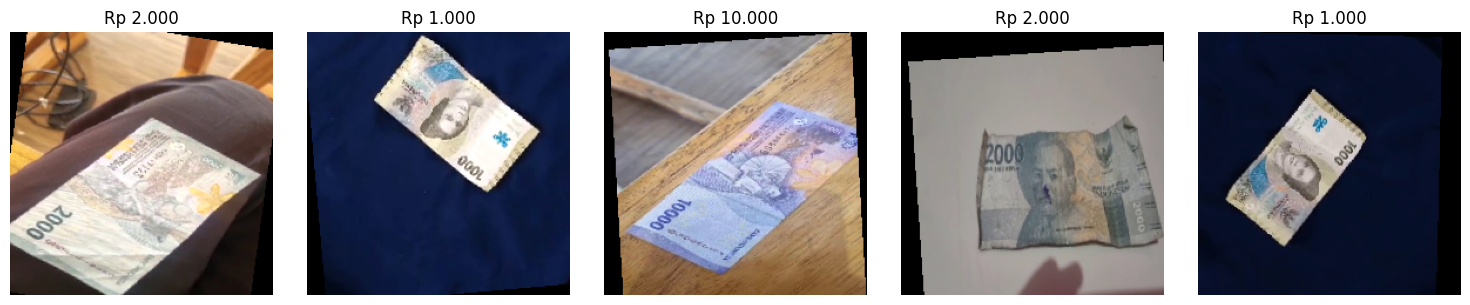

Sampel citra hasil augmentasi training berhasil ditampilkan.


In [7]:
batch_imgs, batch_lbls = next(train_generator)
# Denormalisasi dari [-1, 1] ke [0, 1] untuk visualisasi
disp_imgs = (batch_imgs[:5] + 1.0) / 2.0
disp_imgs = np.clip(disp_imgs, 0.0, 1.0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    axes[i].imshow(disp_imgs[i])
    nominal = CLASSES[np.argmax(batch_lbls[i])]
    axes[i].set_title(f'Rp {int(nominal):,}'.replace(',', '.'))
    axes[i].axis('off')
plt.tight_layout()
plt.show()
print('Sampel citra hasil augmentasi training berhasil ditampilkan.')


## 5. Arsitektur Model


### 5.1. Membangun Model Transfer Learning


In [8]:
def build_mobilenet_v2(num_classes=7, img_size=(224, 224)):
    inputs = layers.Input(shape=(*img_size, 3), name='rupiah_input')
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_tensor=inputs
    )
    base_model.trainable = False

    x = layers.GlobalAveragePooling2D(name='avg_pool')(base_model.output)
    x = layers.BatchNormalization(name='bn_head')(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='dense_head')(x)
    x = layers.Dropout(0.25, name='dropout_head')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = models.Model(inputs, outputs, name='MobileNetV2_Rupiah_V2')
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_FROZEN),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model

model, base_model = build_mobilenet_v2(NUM_CLASSES, IMG_SIZE)
print('Model MobileNetV2 V2 (Optimized) berhasil dibangun.')
print(f'Total layer: {len(model.layers)}, Base model layer: {len(base_model.layers)}')


/tmp/ipykernel_16/1216082239.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(
E0000 00:00:1795245025.004367      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Model MobileNetV2 V2 (Optimized) berhasil dibangun.
Total layer: 159, Base model layer: 154


### 5.2. Ringkasan Arsitektur Model (Summary)


In [9]:
model.summary()


Model: "MobileNetV2_Rupiah_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rupiah_input        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ rupiah_input[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,592,839 (9.89 MB)

 Trainable params: 332,295 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 6. Training Tahap 1: Classifier Head (Backbone Frozen)


In [10]:
callbacks_stage1 = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

print('Memulai Training Tahap 1: Classifier Head (dengan Class Weights)...')
history_stage1 = model.fit(
    train_generator,
    epochs=EPOCHS_FROZEN,
    validation_data=val_generator,
    callbacks=callbacks_stage1,
    class_weight=class_weights,
    verbose=1
)
print('Training Tahap 1 selesai.')
print('Checkpoint model Tahap 1 tersimpan di:', MODEL_SAVE_PATH)


Memulai Training Tahap 1: Classifier Head (dengan Class Weights)...
Epoch 1/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6621 - loss: 1.1324
Epoch 1: val_accuracy improved from None to 0.96286, saving model to /kaggle/working/models/mobilenetv2_frozen.keras

Epoch 1: finished saving model to /kaggle/working/models/mobilenetv2_frozen.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.8248 - loss: 0.6067 - val_accuracy: 0.9629 - val_loss: 0.2769 - learning_rate: 0.0010
Epoch 2/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9694 - loss: 0.1370
Epoch 2: val_accuracy improved from 0.96286 to 0.99714, saving model to /kaggle/working/models/mobilenetv2_frozen.keras

Epoch 2: finished saving model to /kaggle/working/models/mobilenetv2_frozen.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.9788 - loss: 0.1136 - val_accuracy: 0.9971 - val_loss: 0.1183 - learning_rate: 0.0010
Epoch 3/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9891 - loss: 0.0985
Ep

## 7. Training Tahap 2: Fine-Tuning


### 7.1. Unfreeze 40 Layer Backbone


In [11]:
# Unfreeze 40 layer teratas, kunci layer BatchNormalization
UNFREEZE_COUNT = 40
base_model.trainable = True

for layer in base_model.layers[:-UNFREEZE_COUNT]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=LR_FINETUNE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable_params = sum(int(np.prod(v.shape)) for v in model.trainable_weights)
print(f'40 layer teratas dibuka (BatchNormalization tetap dibekukan).')
print(f'Jumlah parameter trainable : {trainable_params:,}')
print(f'Learning rate fine-tuning  : {LR_FINETUNE}')


40 layer teratas dibuka (BatchNormalization tetap dibekukan).
Jumlah parameter trainable : 1,995,655
Learning rate fine-tuning  : 3e-05


### 7.2. Eksekusi Training Fine-Tuning


In [12]:
callbacks_stage2 = [
    EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1),
    ModelCheckpoint(FINETUNE_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

print('Memulai Training Tahap 2: Fine-Tuning (dengan Class Weights)...')
history_stage2 = model.fit(
    train_generator,
    epochs=EPOCHS_FINETUNE,
    validation_data=val_generator,
    callbacks=callbacks_stage2,
    class_weight=class_weights,
    verbose=1
)
print('Training Tahap 2 selesai.')
print('Checkpoint model Tahap 2 tersimpan di:', FINETUNE_SAVE_PATH)


Memulai Training Tahap 2: Fine-Tuning (dengan Class Weights)...
Epoch 1/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9969 - loss: 0.0642
Epoch 1: val_accuracy improved from None to 0.99143, saving model to /kaggle/working/models/mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/models/mobilenetv2_finetuned.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.9958 - loss: 0.0657 - val_accuracy: 0.9914 - val_loss: 0.0771 - learning_rate: 3.0000e-05
Epoch 2/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9935 - loss: 0.0653
Epoch 2: val_accuracy did not improve from 0.99143
52/52 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9952 - loss: 0.0647 - val_accuracy: 0.9829 - val_loss: 0.0980 - learning_rate: 3.0000e-05
Epoch 3/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9953 - loss: 0.0649
Epoch 3: val_accuracy improved from 0.99143 to 0.99429, saving model to /kaggle/working/models/mobilenetv2_finetuned.keras

Epoch 3: finished sa

## 8. Visualisasi Kurva Training


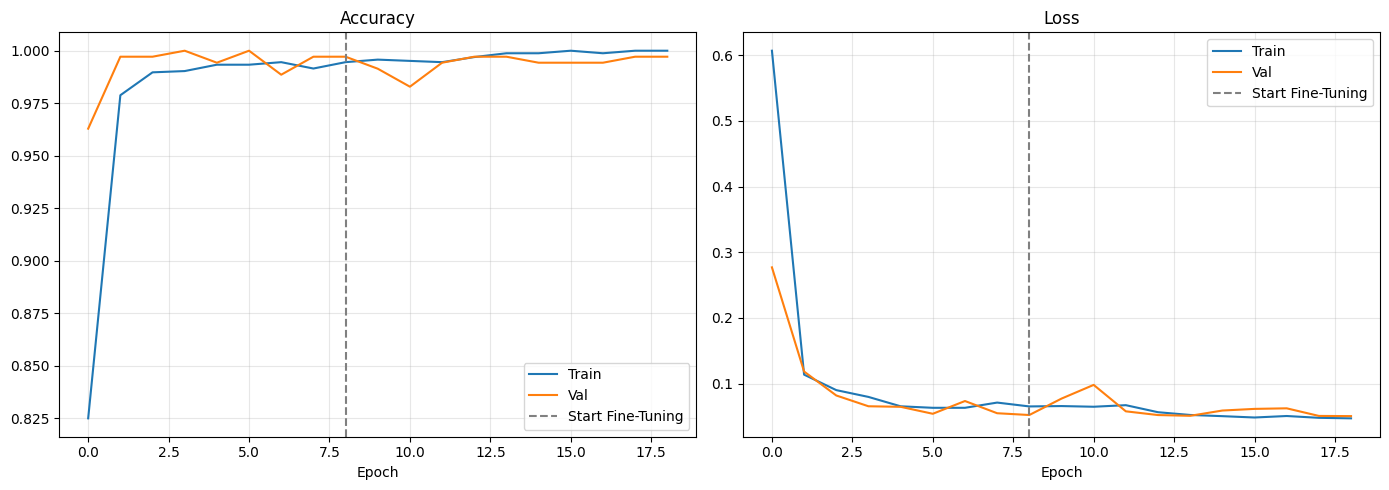

Kurva training (Tahap 1 & 2) berhasil ditampilkan.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']
split_epoch = len(history_stage1.history['accuracy'])

# Plot Akurasi
axes[0].plot(acc, label='Train')
axes[0].plot(val_acc, label='Val')
axes[0].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Loss
axes[1].plot(loss, label='Train')
axes[1].plot(val_loss, label='Val')
axes[1].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('Kurva training (Tahap 1 & 2) berhasil ditampilkan.')


## 9. Evaluasi Model pada Data Test


### 9.1. Evaluasi Model Tahap 1 (Backbone Frozen)


In [14]:
# Memuat model checkpoint terbaik Tahap 1
model_frozen = tf.keras.models.load_model(MODEL_SAVE_PATH)
test_generator.reset()
probs_frozen = model_frozen.predict(test_generator, verbose=1)
pred_frozen  = np.argmax(probs_frozen, axis=1)
y_true       = test_generator.classes

acc_t1 = accuracy_score(y_true, pred_frozen)
p_t1, r_t1, f1_t1, _ = precision_recall_fscore_support(y_true, pred_frozen, average='macro')

print('=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===')
print(f'Test Accuracy  : {acc_t1*100:.2f}%')
print(f'Macro Precision: {p_t1:.4f}')
print(f'Macro Recall   : {r_t1:.4f}')
print(f'Macro F1-Score : {f1_t1:.4f}')


12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 903ms/step
=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===
Test Accuracy  : 99.17%
Macro Precision: 0.9912
Macro Recall   : 0.9912
Macro F1-Score : 0.9912


### 9.2. Evaluasi Model Tahap 2 (Fine-Tuning)


In [15]:
# Memuat model checkpoint terbaik Tahap 2 (atau model saat ini)
model_ft = tf.keras.models.load_model(FINETUNE_SAVE_PATH) if os.path.exists(FINETUNE_SAVE_PATH) else model
test_generator.reset()
probs_ft = model_ft.predict(test_generator, verbose=1)
pred_ft  = np.argmax(probs_ft, axis=1)

acc_t2 = accuracy_score(y_true, pred_ft)
p_t2, r_t2, f1_t2, _ = precision_recall_fscore_support(y_true, pred_ft, average='macro')

print('=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===')
print(f'Test Accuracy  : {acc_t2*100:.2f}%')
print(f'Macro Precision: {p_t2:.4f}')
print(f'Macro Recall   : {r_t2:.4f}')
print(f'Macro F1-Score : {f1_t2:.4f}')


12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 901ms/step
=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===
Test Accuracy  : 100.00%
Macro Precision: 1.0000
Macro Recall   : 1.0000
Macro F1-Score : 1.0000


### 9.3. Tabel Perbandingan Evaluasi (Tahap 1 vs Tahap 2)


In [16]:
df_metrics = pd.DataFrame({
    'Tahapan': ['Tahap 1 (Backbone Frozen)', 'Tahap 2 (Fine-Tuning)', 'Peningkatan'],
    'Test Accuracy': [f'{acc_t1*100:.2f}%', f'{acc_t2*100:.2f}%', f'+{(acc_t2 - acc_t1)*100:.2f}%'],
    'Macro Precision': [f'{p_t1:.4f}', f'{p_t2:.4f}', f'+{(p_t2 - p_t1):.4f}'],
    'Macro Recall': [f'{r_t1:.4f}', f'{r_t2:.4f}', f'+{(r_t2 - r_t1):.4f}'],
    'Macro F1-Score': [f'{f1_t1:.4f}', f'{f1_t2:.4f}', f'+{(f1_t2 - f1_t1):.4f}']
})
print('Tabel Perbandingan Performa Model:')
display(df_metrics)


Tabel Perbandingan Performa Model:


,Tahapan,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Tahap 1 (Backbone Frozen),99.17%,0.9912,0.9912,0.9912
1,Tahap 2 (Fine-Tuning),100.00%,1.0000,1.0000,1.0000
2,Peningkatan,+0.83%,+0.0088,+0.0088,+0.0088


### 9.4. Classification Report


In [17]:
target_names = [f'Rp {int(c):,}'.replace(',', '.') for c in CLASSES]

print('=== Classification Report - Tahap 1 (Backbone Frozen) ===')
print(classification_report(y_true, pred_frozen, target_names=target_names, digits=4))

print('\n=== Classification Report - Tahap 2 (Fine-Tuning) ===')
print(classification_report(y_true, pred_ft, target_names=target_names, digits=4))


=== Classification Report - Tahap 1 (Backbone Frozen) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    1.0000    1.0000        76
    Rp 2.000     1.0000    1.0000    1.0000        54
    Rp 5.000     0.9783    0.9783    0.9783        46
   Rp 10.000     0.9792    0.9792    0.9792        48
   Rp 20.000     0.9811    0.9811    0.9811        53
   Rp 50.000     1.0000    1.0000    1.0000        52
  Rp 100.000     1.0000    1.0000    1.0000        32

    accuracy                         0.9917       361
   macro avg     0.9912    0.9912    0.9912       361
weighted avg     0.9917    0.9917    0.9917       361


=== Classification Report - Tahap 2 (Fine-Tuning) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    1.0000    1.0000        76
    Rp 2.000     1.0000    1.0000    1.0000        54
    Rp 5.000     1.0000    1.0000    1.0000        46
   Rp 10.000     1.0000    1.0000    1.0000        48
   Rp 20.000     1.

### 9.5. Visualisasi Dua Confusion Matrix Berdampingan


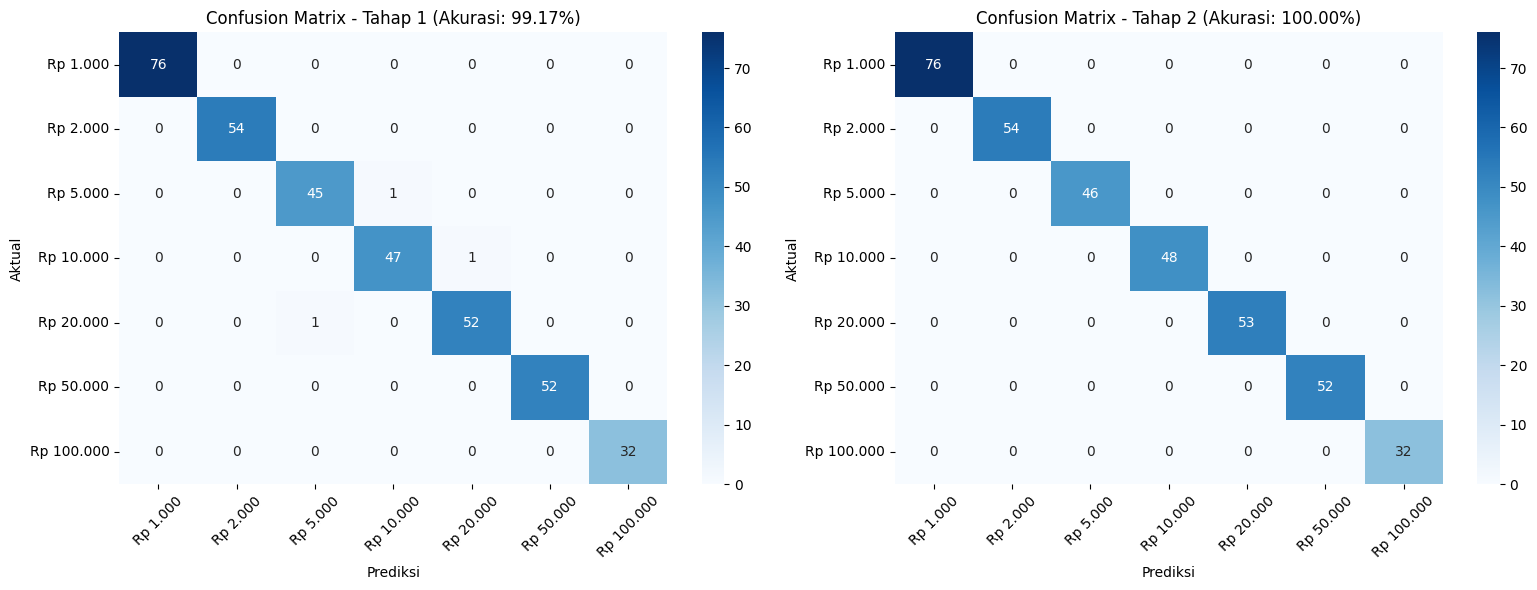

Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan.


In [18]:
cm_t1 = confusion_matrix(y_true, pred_frozen)
cm_t2 = confusion_matrix(y_true, pred_ft)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix Tahap 1
sns.heatmap(cm_t1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f'Confusion Matrix - Tahap 1 (Akurasi: {acc_t1*100:.2f}%)')
axes[0].set_ylabel('Aktual')
axes[0].set_xlabel('Prediksi')
axes[0].tick_params(axis='x', rotation=45)

# Confusion Matrix Tahap 2
sns.heatmap(cm_t2, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title(f'Confusion Matrix - Tahap 2 (Akurasi: {acc_t2*100:.2f}%)')
axes[1].set_ylabel('Aktual')
axes[1].set_xlabel('Prediksi')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
print('Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan.')


## 10. Simpan Model Final


In [19]:
model_ft.save(FINAL_MODEL_PATH)
print('Model final berhasil disimpan ke:', FINAL_MODEL_PATH)

print('\n=== Ringkasan File Model yang Disimpan ===')
saved_items = [
    {
        'Nama File': 'mobilenetv2_frozen.keras',
        'Ukuran': f"{os.path.getsize(MODEL_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(MODEL_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 1 (Backbone Frozen)',
        'Deskripsi / Kegunaan': 'Checkpoint bobot terbaik saat hanya classifier head yang dilatih'
    },
    {
        'Nama File': 'mobilenetv2_finetuned.keras',
        'Ukuran': f"{os.path.getsize(FINETUNE_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINETUNE_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 2 (Fine-Tuning)',
        'Deskripsi / Kegunaan': 'Checkpoint bobot terbaik selama proses fine-tuning'
    },
    {
        'Nama File': 'mobilenetv2_rupiah.keras',
        'Ukuran': f"{os.path.getsize(FINAL_MODEL_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINAL_MODEL_PATH) else '-',
        'Tahapan': 'Model Final (Deployment)',
        'Deskripsi / Kegunaan': 'Model siap pakai untuk inferensi backend API dan aplikasi'
    }
]

df_saved = pd.DataFrame(saved_items)
display(df_saved)


Model final berhasil disimpan ke: /kaggle/working/models/mobilenetv2_rupiah.keras

=== Ringkasan File Model yang Disimpan ===


,Nama File,Ukuran,Tahapan,Deskripsi / Kegunaan
0,mobilenetv2_frozen.keras,12.99 MB,Tahap 1 (Backbone Frozen),Checkpoint bobot terbaik saat hanya classifier...
1,mobilenetv2_finetuned.keras,25.69 MB,Tahap 2 (Fine-Tuning),Checkpoint bobot terbaik selama proses fine-tu...
2,mobilenetv2_rupiah.keras,25.69 MB,Model Final (Deployment),Model siap pakai untuk inferensi backend API d...
